1. P_req aus power profile
2. Abgleich mit Convertern ratings (ggf. anfallende mismatches schon hier loggen)
3. Logik, um split aus P_bat und P_sc zu bestimmen, wobei der SC die high freq power spikes abfangen sollte
4. SC wird gestepped, P_sc_actual wird aus sc.state.power ausgelesen
5. Battery wird um P_bat + dem delta aus P_sc und P_sc_ac gestepped
6. Jegliche over oder underflows werden gelogged

In [62]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from simses.model.converter.fix_efficiency import FixedEfficiency
from simses.model.converter.sinamics import SinamicsS120

from hess import HybridController

%matplotlib inline
DATA_FULL = r"./_processed_profiles/stitched_profiles.csv"
df = pd.read_csv(DATA_FULL)

In [63]:
y = -df.loc[df["segment_id"] == 1]["node_gpu_power_W"]
p_bat_init = y[0]
y = y[1:]
x = np.diff(df.loc[df["segment_id"] == 1]["time_s"])

In [65]:
taus = [0.001, 0.1, 2, 5, 10, 25, 50, 75, 100, 250, 500, 750, 1000]

logs = {
    tau : None for tau in taus
}

for tau in taus:
    hc = HybridController.build_controller(tau, converter_model = lambda: FixedEfficiency(1))

    for time, power in zip(x,y):
        hc.step(power, time)
    
    logs[tau] = pd.DataFrame(hc.log)

In [66]:
[logs[tau]["loss_fraction"].iloc[-1] for tau in taus]

[np.float64(0.047356969105784914),
 np.float64(0.04723604315783864),
 np.float64(0.04072860894290271),
 np.float64(0.03733447847793592),
 np.float64(0.03520906170359577),
 np.float64(0.03038191892445341),
 np.float64(0.023212868113548498),
 np.float64(0.017759410439724045),
 np.float64(0.013947280599024921),
 np.float64(0.005736301325855265),
 np.float64(0.003564267205793524),
 np.float64(0.003029853266188779),
 np.float64(0.0027807930928652413)]

In [67]:
[logs[tau]["error_fraction"].iloc[-1] for tau in taus]

[np.float64(0.0),
 np.float64(0.0),
 np.float64(5.1219048535622366e-20),
 np.float64(1.0243809707124473e-19),
 np.float64(2.0487619414248946e-19),
 np.float64(6.146285824274673e-19),
 np.float64(8.195047765699614e-19),
 np.float64(1.690228601675523e-18),
 np.float64(2.8170476694592474e-18),
 np.float64(5.787752484525312e-18),
 np.float64(0.08762852528903163),
 np.float64(0.13702201093540534),
 np.float64(0.1631710199563301)]

0.5751075499544992
0.3335024152654901
0.017759410439724045
1.690228601675523e-18


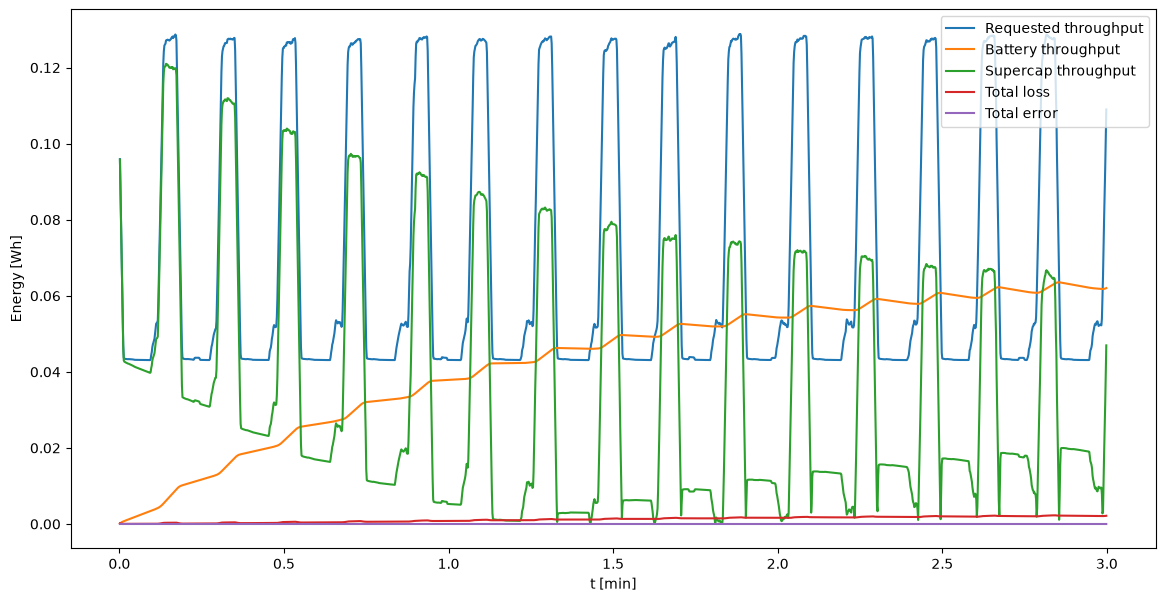

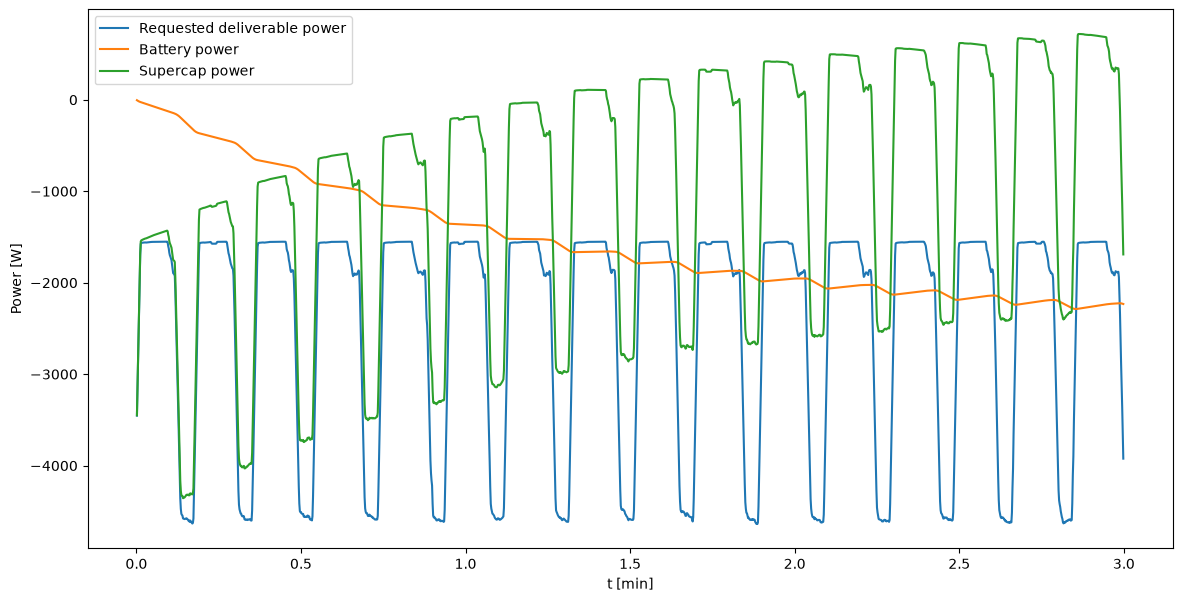

In [68]:
i = 75

x_axis = df.loc[df["segment_id"] == 1]["time_s"][1:]/60

plt.figure(figsize=(14,7))
plt.plot(
    x_axis,
    logs[i]["dE_total_thr"],
    label="Requested throughput"
)
plt.plot(
    x_axis,
    logs[i]["dE_bat_thr"],
    label="Battery throughput"
)
plt.plot(
    x_axis,
    logs[i]["dE_sc_thr"],
    label="Supercap throughput"
)
plt.plot(
    x_axis,
    logs[i]["dE_total_loss"],
    label="Total loss"
)
plt.plot(
    x_axis,
    logs[i]["dE_total_error"],
    label="Total error"
)
plt.xlabel("t [min]")
plt.ylabel("Energy [Wh]")

plt.legend()

plt.figure(figsize=(14,7))
plt.plot(
    x_axis,
    logs[i]["p_total_actual"],
    label="Requested deliverable power"
)
plt.plot(
    x_axis,
    logs[i]["p_bat_actual"],
    label="Battery power"
)
plt.plot(
    x_axis,
    logs[i]["p_sc_actual"],
    label="Supercap power"
)
plt.xlabel("t [min]")
plt.ylabel("Power [W]")

plt.legend()

print(logs[i]["bat_soc"].iloc[-1])
print(logs[i]["sc_soc"].iloc[-1])
print(logs[i]["loss_fraction"].iloc[-1])
print(logs[i]["error_fraction"].iloc[-1])